In [1]:
import pandas as pd
import numpy as np
from pandas.api.types import is_numeric_dtype

# Предпросмотр

In [2]:
df = pd.read_csv("data/data.csv")

/tmp/ipykernel_13054/950551662.py:1: DtypeWarning: Columns (0: anzart_genossenschaft_janein, 1: aus_alarmanlage_janein, 2: aus_lastenaufzug_janein, 3: aus_pool_janein) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/data.csv")


In [3]:
print("Shape:", df.shape)

display(df.head())

Shape: (144778, 152)


,angebot_id,aadr_gewerblich_janein,anz_balkon_terrasse,anz_einheiten,anz_einheiten_gesamt,anz_einheiten_gewerbe,anz_einheiten_gewerbe_gesamt,anz_einheiten_wohnen,anz_einheiten_wohnen_gesamt,anz_gebaeude,...,zust_klassen5,zust_modernisierungsjahr,zust_neuwertig_janein,zust_projektiert_janein,zust_renoviert_janein,zust_renovierungsbedarf_janein,zust_renovierungsjahr,zust_saniert_janein,zust_sanierungsbedarf_janein,zust_sanierungsjahr
0,3541789429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3632139119,True,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1,2006.0,NaN,NaN,False,True,NaN,NaN,True,2006.0
2,3632412028,True,2.0,NaN,2.0,NaN,NaN,NaN,2.0,NaN,...,4,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3632651609,True,1.0,NaN,20.0,NaN,NaN,NaN,20.0,NaN,...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3632945773,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3,2014.0,NaN,NaN,NaN,NaN,NaN,True,NaN,2014.0


In [4]:
df.columns.tolist()

['angebot_id',
 'aadr_gewerblich_janein',
 'anz_balkon_terrasse',
 'anz_einheiten',
 'anz_einheiten_gesamt',
 'anz_einheiten_gewerbe',
 'anz_einheiten_gewerbe_gesamt',
 'anz_einheiten_wohnen',
 'anz_einheiten_wohnen_gesamt',
 'anz_gebaeude',
 'anz_parken',
 'anz_parken_carports',
 'anz_parken_garagen',
 'anz_parken_parkhaus',
 'anz_parken_stellplaetze',
 'anz_parken_tiefgaragen',
 'anz_zimmer',
 'anzart_genossenschaft_janein',
 'anzart_indexmiete_janein',
 'anzart_nachmieter_janein',
 'anzart_waz_moebliert_janein',
 'anzart_wohnen_auf_zeit_janein',
 'aus_abstellraum_janein',
 'aus_alarmanlage_janein',
 'aus_bad_dusche_janein',
 'aus_bad_gaestewc_janein',
 'aus_bad_mit_fenster_janein',
 'aus_bad_wanne_janein',
 'aus_balkon_janein',
 'aus_barrierefrei_janein',
 'aus_boden_estrich_janein',
 'aus_boden_fliesen_janein',
 'aus_boden_kunststoff_janein',
 'aus_boden_laminat_janein',
 'aus_boden_linoleum_janein',
 'aus_boden_marmor_janein',
 'aus_boden_parkett_janein',
 'aus_boden_teppich_janei

In [5]:
df.dtypes

angebot_id                          int64
aadr_gewerblich_janein             object
anz_balkon_terrasse               float64
anz_einheiten                     float64
anz_einheiten_gesamt              float64
                                   ...   
zust_renovierungsbedarf_janein     object
zust_renovierungsjahr             float64
zust_saniert_janein                object
zust_sanierungsbedarf_janein       object
zust_sanierungsjahr               float64
Length: 152, dtype: object

анализ что можно дропнуть, где наны, какие значения встречаются

In [6]:
def display_nan_stats(df):
    nan_stats = pd.DataFrame({
        "dtype": df.dtypes,
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(2),
        "unique_count": df.nunique(),
        "values": [
            "" if is_numeric_dtype(df[col])
            else df[col].dropna().unique().tolist()
            for col in df.columns
        ]
    })

    nan_stats = nan_stats.sort_values(
        "missing_percent",
        ascending=False
    )

    with pd.option_context(
        "display.max_rows", None,
        "display.max_colwidth", None
    ):
        display(nan_stats)

    return nan_stats

display_nan_stats(df)

,dtype,missing_count,missing_percent,unique_count,values
anzart_wohnen_auf_zeit_janein,float64,144778,100.00,0,
anzart_waz_moebliert_janein,float64,144778,100.00,0,
oadr_ortz_reg,float64,144778,100.00,0,
anz_parken_parkhaus,float64,144768,99.99,3,
aus_lastenaufzug_janein,object,144769,99.99,1,[True]
anzart_genossenschaft_janein,object,144677,99.93,1,[True]
aus_boden_terrakotta_janein,object,144547,99.84,1,[True]
anz_gebaeude,float64,144511,99.82,4,
anz_einheiten_gewerbe,float64,144447,99.77,11,
anz_einheiten_gewerbe_gesamt,float64,144362,99.71,21,


,dtype,missing_count,missing_percent,unique_count,values
anzart_wohnen_auf_zeit_janein,float64,144778,100.00,0,
anzart_waz_moebliert_janein,float64,144778,100.00,0,
oadr_ortz_reg,float64,144778,100.00,0,
anz_parken_parkhaus,float64,144768,99.99,3,
aus_lastenaufzug_janein,object,144769,99.99,1,[True]
...,...,...,...,...,...
objekttyp_fein,int64,0,0.00,13,
objekttyp_grob,int64,0,0.00,3,
zust_klassen5,int64,0,0.00,5,
startdate,str,0,0.00,1802,"[2022-11-16, 2024-10-07, 2024-10-09, 2024-10-1..."


перевести в False все NaN, если из возможных значений только True

In [7]:
def fill_missing_false_for_true_only(df):
    df = df.copy()
    processed_columns = []

    for col in df.columns:
        values = set(df[col].dropna().unique())

        if values == {True}:
            df[col] = df[col].fillna(False)
            processed_columns.append(col)

    print(f"Processed {len(processed_columns)} columns:")
    print(processed_columns)

    return df

df = fill_missing_false_for_true_only(df)
nan_stats = display_nan_stats(df)

Processed 51 columns:
['aadr_gewerblich_janein', 'anzart_genossenschaft_janein', 'anzart_indexmiete_janein', 'anzart_nachmieter_janein', 'aus_abstellraum_janein', 'aus_alarmanlage_janein', 'aus_bad_dusche_janein', 'aus_bad_gaestewc_janein', 'aus_bad_mit_fenster_janein', 'aus_bad_wanne_janein', 'aus_balkon_janein', 'aus_barrierefrei_janein', 'aus_boden_estrich_janein', 'aus_boden_fliesen_janein', 'aus_boden_kunststoff_janein', 'aus_boden_laminat_janein', 'aus_boden_linoleum_janein', 'aus_boden_marmor_janein', 'aus_boden_parkett_janein', 'aus_boden_teppich_janein', 'aus_boden_terrakotta_janein', 'aus_dachterrasse_janein', 'aus_garten_janein', 'aus_hauswirtschaftsraum_janein', 'aus_heiz_fernwaerme_janein', 'aus_heiz_fussboden_janein', 'aus_kamin_janein', 'aus_kueche_einbau_janein', 'aus_kueche_offen_janein', 'aus_lastenaufzug_janein', 'aus_lift_janein', 'aus_parken_garage_janein', 'aus_parken_janein', 'aus_parken_ladestation_janein', 'aus_parken_stellplaetze_janein', 'aus_parken_tiefgarag

,dtype,missing_count,missing_percent,unique_count,values
anzart_wohnen_auf_zeit_janein,float64,144778,100.00,0,
anzart_waz_moebliert_janein,float64,144778,100.00,0,
oadr_ortz_reg,float64,144778,100.00,0,
anz_parken_parkhaus,float64,144768,99.99,3,
anz_gebaeude,float64,144511,99.82,4,
anz_einheiten_gewerbe,float64,144447,99.77,11,
anz_einheiten_gewerbe_gesamt,float64,144362,99.71,21,
anz_parken_carports,float64,143186,98.90,4,
oeig_flachdach_janein,object,138458,95.63,2,"[False, True]"
oeig_freistehend_janein,object,137070,94.68,2,"[False, True]"


In [8]:
nan_stats.to_csv("nan_stats.csv", index=True)

In [9]:
def inspect_feature(df, col):
    s = df[col]

    print(f"Feature: {col}")
    print(f"dtype: {s.dtype}")
    print(f"rows: {len(s)}")
    print(f"missing: {s.isna().sum()} ({s.isna().mean() * 100:.2f}%)")
    print(f"unique: {s.nunique(dropna=True)}")

    if pd.api.types.is_numeric_dtype(s):
        print("\nNumeric stats:")
        print(s.describe())

        print("\nSample values:")
        print(s.dropna().head(10).tolist())

    else:
        print("\nMost common values:")
        print(s.value_counts(dropna=False).head(15))

        print("\nSample values:")
        print(s.dropna().head(10).tolist())

In [10]:
#df["kstn_miete_gesamt_pqm"].tail(500)
inspect_feature(df, "objekttyp_fein")

Feature: objekttyp_fein
dtype: int64
rows: 144778
missing: 0 (0.00%)
unique: 13

Numeric stats:
count    144778.000000
mean          2.960947
std           2.637850
min           1.000000
25%           2.000000
50%           2.000000
75%           3.000000
max          33.000000
Name: objekttyp_fein, dtype: float64

Sample values:
[1, 1, 3, 3, 1, 3, 2, 2, 3, 1]


Дальше я вручную отобрал фичи, с которых хочу начать

# Первые модели

In [11]:
start_features = ['aus_boden_kunststoff_janein',
                  'aus_boden_laminat_janein',
                  'aus_boden_linoleum_janein',
                  'aus_boden_marmor_janein',
                  'aus_balkon_janein',
                  'aus_boden_estrich_janein', 
                  'aus_terrasse_janein',
                  'aus_boden_fliesen_janein',
                  'aus_boden_terrakotta_janein',
                  'aus_boden_parkett_janein',
                  'aus_heiz_fernwaerme_janein',
                  'aus_heiz_fussboden_janein',
                  'aus_kueche_einbau_janein',
                  'aus_kueche_offen_janein',
                  'oeig_neubau_janein',
                  'objekttyp_fein',
                  'aus_boden_teppich_janein',
                  'flaeche', # new features
                  'oeig_keller_janein',
                  'baujahr',
                  'etage',
                  'anz_zimmer',
                  'aus_klassen5',
                  'aadr_gewerblich_janein',
                  'aus_alarmanlage_janein',
                  'aus_abstellraum_janein',
                  'anzart_indexmiete_janein',
                  'anzart_nachmieter_janein',
                  'anzart_genossenschaft_janein',
                  'aus_bad_dusche_janein',
                  'aus_bad_mit_fenster_janein',
                  'aus_bad_gaestewc_janein',
                  'aus_barrierefrei_janein',
                  'aus_bad_wanne_janein',
                  'energie_niedrig_janein',
                  'aus_pool_janein',
                  'aus_sauna_janein',
                  'aus_parken_tiefgarage_janein',
                  'aus_hauswirtschaftsraum_janein',
                  'aus_garten_janein',
                  'aus_kamin_janein',
                  'aus_lastenaufzug_janein',
                  'aus_lift_janein',
                  'aus_parken_garage_janein',
                  'aus_parken_janein',
                  'aus_parken_ladestation_janein',
                  'oeig_loggia_janein',
                  'oeig_galerie_janein',
                  'zust_gepflegt_janein',
                  'zust_projektiert_janein',
                  'zust_sanierungsbedarf_janein',
                 ]

df = df[start_features + ['kosten_je_flaeche']].copy()

In [12]:
df = pd.get_dummies(
    df,
    columns=["objekttyp_fein", 'aus_klassen5'],
    dtype=int
) # one-hot encoding 
df = df.dropna()

In [13]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("boolean")

In [14]:
df.shape

(91012, 68)

In [15]:
display_nan_stats(df)

,dtype,missing_count,missing_percent,unique_count,values
aus_boden_kunststoff_janein,boolean,0,0.0,2,
aus_boden_laminat_janein,boolean,0,0.0,2,
aus_boden_linoleum_janein,boolean,0,0.0,2,
aus_boden_marmor_janein,boolean,0,0.0,2,
aus_balkon_janein,boolean,0,0.0,2,
aus_boden_estrich_janein,boolean,0,0.0,2,
aus_terrasse_janein,boolean,0,0.0,2,
aus_boden_fliesen_janein,boolean,0,0.0,2,
aus_boden_terrakotta_janein,boolean,0,0.0,2,
aus_boden_parkett_janein,boolean,0,0.0,2,


,dtype,missing_count,missing_percent,unique_count,values
aus_boden_kunststoff_janein,boolean,0,0.0,2,
aus_boden_laminat_janein,boolean,0,0.0,2,
aus_boden_linoleum_janein,boolean,0,0.0,2,
aus_boden_marmor_janein,boolean,0,0.0,2,
aus_balkon_janein,boolean,0,0.0,2,
...,...,...,...,...,...
aus_klassen5_0.0,int64,0,0.0,2,
aus_klassen5_1.0,int64,0,0.0,2,
aus_klassen5_2.0,int64,0,0.0,2,
aus_klassen5_3.0,int64,0,0.0,2,


In [16]:
df.dtypes

aus_boden_kunststoff_janein    boolean
aus_boden_laminat_janein       boolean
aus_boden_linoleum_janein      boolean
aus_boden_marmor_janein        boolean
aus_balkon_janein              boolean
                                ...   
aus_klassen5_0.0                 int64
aus_klassen5_1.0                 int64
aus_klassen5_2.0                 int64
aus_klassen5_3.0                 int64
aus_klassen5_4.0                 int64
Length: 68, dtype: object

In [17]:
corr = df.astype(float).corr()
#display(corr)

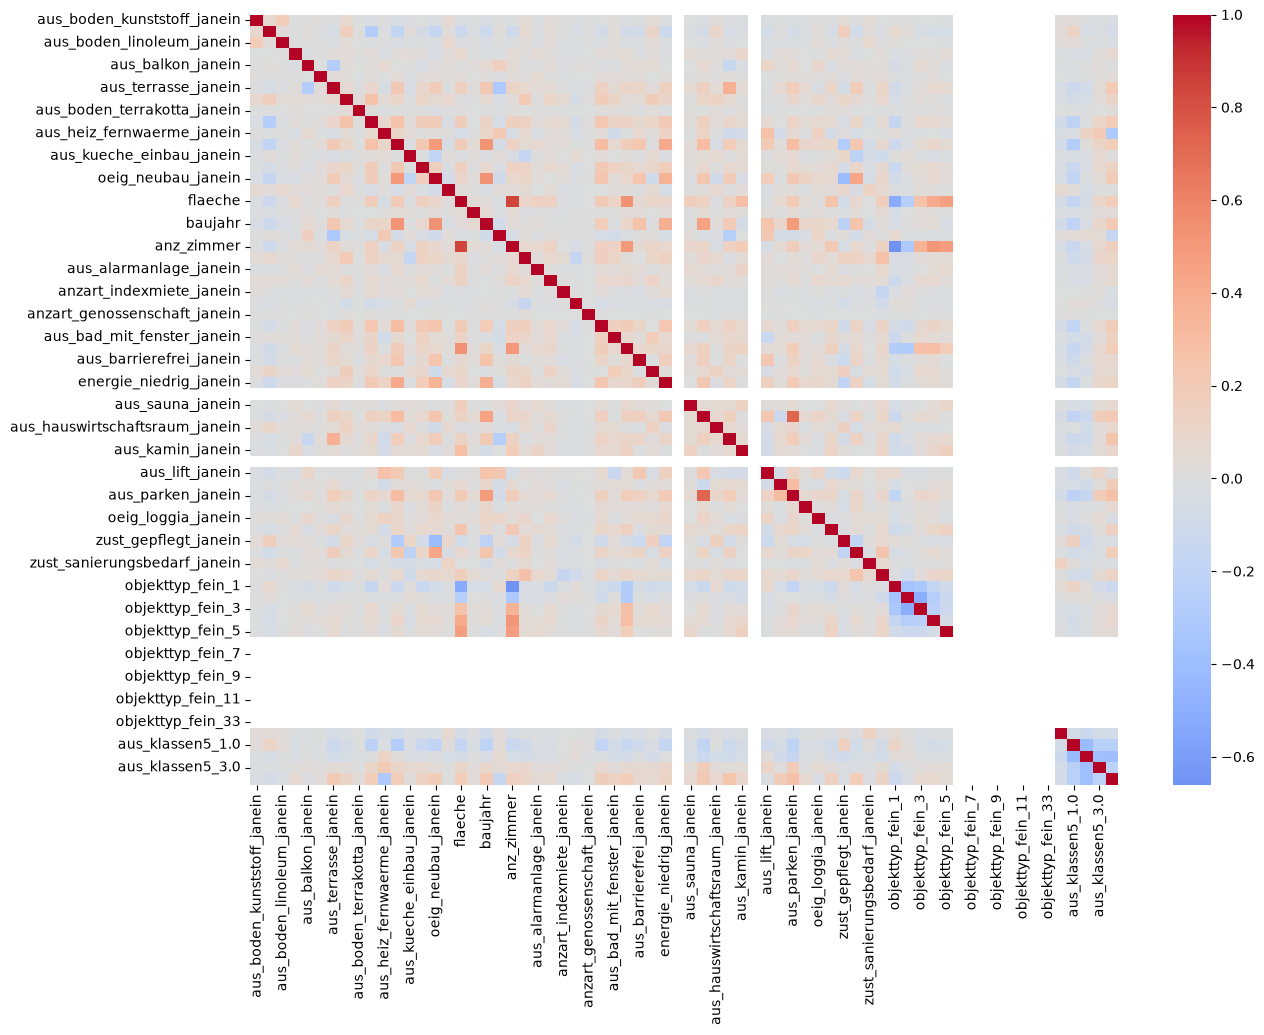

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)
plt.show()

корреляция почти нет, только горячий пол с новизной здания и размер с ценой и конкретным типом помещения.

In [19]:
from utils import train_model, evaluate_model

In [20]:
target = "kosten_je_flaeche"

X = df.drop(columns=[target])
y = df[target]

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

## Линейная модель

In [22]:
from models import linear
model = linear.build_model()

training_result = train_model(
    model,
    X_train,
    y_train
)
best_model = training_result["model"]
training_result

{'model': LinearRegression(),
 'best_params': None,
 'cv_metrics': None,
 'search': None}

In [23]:
test_result = evaluate_model(
    best_model,
    X_test,
    y_test
)

test_result

{'rmse': np.float64(4558.515724696784),
 'mae': 3717.376263826163,
 'r2': 0.21763577311585347,
 'predictions': array([3300.443543  , 3872.26627266, 2711.0776955 , ..., 4341.58125032,
        9920.92246373, 7999.20566445], shape=(18203,))}

In [24]:
print(y.describe())

count    91012.000000
mean      4023.032976
std       5122.257225
min          3.330000
25%         20.000000
50%         26.830000
75%       8260.870000
max      29914.530000
Name: kosten_je_flaeche, dtype: float64


## Дерево

In [25]:
%%time
from models import regression_tree
model = regression_tree.build_model()

training_result = train_model(
    model,
    X_train,
    y_train,
    param_grid=regression_tree.get_param_grid(),
    cv=5
)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
CPU times: user 2.05 s, sys: 893 ms, total: 2.95 s
Wall time: 6.58 s


In [26]:
print(training_result["best_params"])
print(training_result["cv_metrics"])
best_model = training_result["model"]
test_result = evaluate_model(
    best_model,
    X_test,
    y_test
)

test_result

{'criterion': 'squared_error', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2, 'splitter': 'best'}
{'rmse': np.float64(4484.03785987809), 'rmse_std': np.float64(38.34803774159847), 'mae': np.float64(3554.630369081512), 'mae_std': np.float64(32.443201681184895), 'r2': np.float64(0.2311222771624705), 'r2_std': np.float64(0.008101463195140329)}


{'rmse': np.float64(4491.105019801282),
 'mae': 3555.119833738604,
 'r2': 0.24060367463495846,
 'predictions': array([ 2065.14434257,  2444.26422516,  1539.35506778, ...,
         5139.13765453, 11357.89489848,  7671.45258348], shape=(18203,))}

## Случайный лес

In [27]:
%%time
from models import random_forest
model = random_forest.build_model()

training_result = train_model(
    model,
    X_train,
    y_train,
    param_grid=random_forest.get_param_grid(),
    cv=5
)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
CPU times: user 1min 21s, sys: 1.06 s, total: 1min 22s
Wall time: 7min 18s


In [28]:
print(training_result["best_params"])
print(training_result["cv_metrics"])
best_model = training_result["model"]
test_result = evaluate_model(
    best_model,
    X_test,
    y_test
)

test_result

{'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 300}
{'rmse': np.float64(4065.340607903819), 'rmse_std': np.float64(43.7248487952898), 'mae': np.float64(3133.4009353856754), 'mae_std': np.float64(39.463186952956164), 'r2': np.float64(0.368028368057643), 'r2_std': np.float64(0.007073798115239126)}


{'rmse': np.float64(4043.1077280500517),
 'mae': 3086.3517618332294,
 'r2': 0.3845501129680401,
 'predictions': array([ 2590.50846677,   802.53422111,  2390.03615211, ...,
         5521.59391463, 12490.47203856,  7561.74462555], shape=(18203,))}

## Бустинг

In [29]:
%%time
from models import gradient_boosting
model = gradient_boosting.build_model()

training_result = train_model(
    model,
    X_train,
    y_train,
    param_grid=gradient_boosting.get_param_grid(),
    cv=5
)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
CPU times: user 26.4 s, sys: 813 ms, total: 27.2 s
Wall time: 3min 38s


In [30]:
print(training_result["best_params"])
print(training_result["cv_metrics"])
best_model = training_result["model"]
test_result = evaluate_model(
    best_model,
    X_test,
    y_test
)

test_result

{'learning_rate': 0.1, 'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 250, 'subsample': 0.8}
{'rmse': np.float64(4185.61059342819), 'rmse_std': np.float64(40.28124209244282), 'mae': np.float64(3335.152371893698), 'mae_std': np.float64(30.042247640231132), 'r2': np.float64(0.3300887545437097), 'r2_std': np.float64(0.00524225700721192)}


{'rmse': np.float64(4184.971972733443),
 'mae': 3323.471553541296,
 'r2': 0.3406026802597497,
 'predictions': array([ 3001.21625925,  2234.2214554 ,  2339.42750858, ...,
         5465.56407856, 13338.7052206 ,  8282.71442219], shape=(18203,))}

In [31]:
%%time
from utils import train_model, evaluate_model
from models import xgboost
import cupy as cp

X_train_gpu = cp.asarray(
    X_train.astype(np.float32).to_numpy()
)

y_train_gpu = cp.asarray(
    y_train.astype(np.float32).to_numpy()
)

X_test_gpu = cp.asarray(
    X_test.astype(np.float32).to_numpy()
)
    
y_test_gpu = cp.asarray(
    y_test.astype(np.float32).to_numpy()
)

model = xgboost.build_model()

# training_result = train_model(
#     model,
#     X_train,
#     y_train,
#     param_grid=xgboost.get_param_grid(),
#     cv=5,
#     n_jobs=1
# )

CPU times: user 74.8 ms, sys: 229 ms, total: 304 ms
Wall time: 492 ms


In [32]:
print(training_result["best_params"])
print(training_result["cv_metrics"])
best_model = training_result["model"]
test_result = evaluate_model(
    best_model,
    X_test,
    y_test
)

test_result

{'learning_rate': 0.1, 'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 250, 'subsample': 0.8}
{'rmse': np.float64(4185.61059342819), 'rmse_std': np.float64(40.28124209244282), 'mae': np.float64(3335.152371893698), 'mae_std': np.float64(30.042247640231132), 'r2': np.float64(0.3300887545437097), 'r2_std': np.float64(0.00524225700721192)}


{'rmse': np.float64(4184.971972733443),
 'mae': 3323.471553541296,
 'r2': 0.3406026802597497,
 'predictions': array([ 3001.21625925,  2234.2214554 ,  2339.42750858, ...,
         5465.56407856, 13338.7052206 ,  8282.71442219], shape=(18203,))}

## KNN

In [33]:
%%time
from models import knn

model = knn.build_model()

training_result = train_model(
    model,
    X_train,
    y_train,
    param_grid=knn.get_param_grid(),
    cv=5,
    n_jobs=1
)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
[CV] END model__algorithm=brute, model__n_neighbors=5, model__p=1, model__weights=uniform; total time=   2.6s
[CV] END model__algorithm=brute, model__n_neighbors=5, model__p=1, model__weights=uniform; total time=   2.5s
[CV] END model__algorithm=brute, model__n_neighbors=5, model__p=1, model__weights=uniform; total time=   6.1s
[CV] END model__algorithm=brute, model__n_neighbors=5, model__p=1, model__weights=uniform; total time=   2.6s
[CV] END model__algorithm=brute, model__n_neighbors=5, model__p=1, model__weights=uniform; total time=   2.6s
[CV] END model__algorithm=brute, model__n_neighbors=5, model__p=1, model__weights=distance; total time=   2.6s
[CV] END model__algorithm=brute, model__n_neighbors=5, model__p=1, model__weights=distance; total time=   2.6s
[CV] END model__algorithm=brute, model__n_neighbors=5, model__p=1, model__weights=distance; total time=   2.6s
[CV] END model__algorithm=brute, model__n_neighbors=5, m

In [34]:
print(training_result["best_params"])
print(training_result["cv_metrics"])

best_model = training_result["model"]
test_result = evaluate_model(
    best_model,
    X_test,
    y_test
)

test_result

{'model__algorithm': 'brute', 'model__n_neighbors': 25, 'model__p': 1, 'model__weights': 'distance'}
{'rmse': np.float64(4201.983615706828), 'rmse_std': np.float64(50.54562776104208), 'mae': np.float64(3251.3933126424286), 'mae_std': np.float64(34.34732826442594), 'r2': np.float64(0.3248532627290226), 'r2_std': np.float64(0.007294599286818916)}


{'rmse': np.float64(4167.424971476737),
 'mae': 3180.825497667744,
 'r2': 0.34612060919431253,
 'predictions': array([ 2769.7956399 ,  1361.36394751,  4112.1353531 , ...,
         5606.81018986, 11797.52642967,  5216.26395972], shape=(18203,))}

[CV] END criterion=squared_error, max_depth=None, min_samples_leaf=1, min_samples_split=2, splitter=best; total time=   0.8s
[CV] END criterion=squared_error, max_depth=None, min_samples_leaf=5, min_samples_split=10, splitter=best; total time=   0.7s
[CV] END criterion=squared_error, max_depth=5, min_samples_leaf=1, min_samples_split=2, splitter=best; total time=   0.2s
[CV] END criterion=squared_error, max_depth=5, min_samples_leaf=1, min_samples_split=50, splitter=best; total time=   0.2s
[CV] END criterion=squared_error, max_depth=5, min_samples_leaf=20, min_samples_split=10, splitter=best; total time=   0.2s
[CV] END criterion=squared_error, max_depth=10, min_samples_leaf=1, min_samples_split=50, splitter=best; total time=   0.4s
[CV] END criterion=squared_error, max_depth=10, min_samples_leaf=20, min_samples_split=10, splitter=best; total time=   0.4s
[CV] END criterion=squared_error, max_depth=20, min_samples_leaf=5, min_samples_split=2, splitter=best; total time=   0.7s
[CV] END